# П4 (пары B и C): одна модель — семейство сэмплеров

**Задание.** Взять скорость из П3, пересчитать её в score и сэмплировать SDE-семейством с разными $g$ (0, 0.5, 1, 2) при NFE от 5 до 100. То же — с точными полями оракула. Обратно: score-модель из П2 пересчитать в скорость и интегрировать как ODE. Вопрос: **когда шум в сэмплере помогает?** Гипотеза: с точным оракулом и малым NFE лучше ODE, а при неидеальной модели умеренный $g$ частично исправляет её ошибку.

**Готово, когда:** есть тепловая карта «качество vs $(g,\text{NFE})$» для оракула и для обученной модели и вывод в одном предложении.

## Теория (Т4, пп. 3–4)

Все сэмплеры живут на пути Rectified Flow: $x_t = t\,x_1 + (1-t)\,x_0$, $x_0\sim\mathcal N(0,I)$ — шум, $x_1$ — данные, время идёт **от шума ($t=0$) к данным ($t=1$)**.

**Связь скорости и score** для гауссова пути $x_t = \alpha_t x_1 + \sigma_t x_0$:
$$v_t(x) = \frac{\dot\alpha_t}{\alpha_t}x + \sigma_t\Big(\frac{\dot\alpha_t\sigma_t}{\alpha_t} - \dot\sigma_t\Big)\nabla\log p_t(x)
\quad\xrightarrow{\ \alpha=t,\ \sigma=1-t\ }\quad
v = \frac{x}{t} + \frac{1-t}{t}\,s, \qquad s = \frac{t\,v - x}{1-t}.$$

**Семейство с общими маргиналами.** При любом $g_t$
$$dx = \Big[v_t(x) + \tfrac12 g_t^2\,\nabla\log p_t(x)\Big]dt + g_t\,dW$$
имеет те же $p_t$, что и ODE $dx = v_t\,dt$ (подставить в Фоккера–Планка: $-\nabla\cdot(\tfrac12 g^2 p\nabla\log p) + \tfrac12 g^2\Delta p = 0$). $g=0$ — это ODE.

## Три поля $(v, s)$ — «одна модель», три источника

| Поле | Что обучено | Как получаем второе поле |
|---|---|---|
| **оракул** | ничего: точные $v$ и $s$ смеси гауссиан | — |
| **скорость (RF)** | сеть $v_\theta$ по лоссу слайда 39 | $s = (t v - x)/(1-t)$ |
| **score (VP, П2)** | score-сеть из П2 | перенос на путь RF, затем $v = x/t + \tfrac{1-t}{t}s$ |

Модель скорости здесь — **временная замена П3**: обучена тем же лоссом, что у пары C. Когда будет готова их модель, её подставляют в `load_rf_model()` в `p4_experiments.py`, и весь ноутбук пересчитывается.

**Перенос score с VP на путь RF.** Все гауссовы пути отличаются только масштабом и «шумностью» $\lambda = \sigma/\alpha$: путь RF в момент $t$ — это $\alpha_t(x_1 + \lambda z)$, VP в момент $\tau$ — $a(\tau)(x_1 + \lambda z)$. Находим $\tau$ с тем же $\lambda$ и масштабируем: $\nabla\log p^{RF}_t(x) = \tfrac{a}{\alpha_t}\, s^{VP}\big(\tfrac{a}{\alpha_t}x,\ \tau\big)$. Одна score-модель годится для любого гауссова пути.

**Сетка.** $t$ от 0.01 до 0.99 (на концах формулы связи делят на ноль); старт $x\sim\mathcal N(0, 0.99^2 I)$; в конце делим на $t=0.99$, возвращая масштаб данных. Эйлер–Маруяма, NFE = число шагов (на шаге один вызов сети: второе поле пересчитывается из первого).

**Метрики** — как в П2: Sliced W1 до данных (пол ≈ 0.034) и TV по долям мод (пол ≈ 0.01); 3 сида, 10⁴ точек.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from p4_experiments import (GS, NFES4, SEEDS4, N4, T0, T1, FIELD_NAMES, load_or_run, grid, field_error,
                            get_field, load_rf_model, mix, reference_sample)
from p2_experiments import metric_floor
from common.paths import sample_family

floor = load_or_run('results/floor.pt', metric_floor)
FLOOR_SW, FLOOR_TV = floor['sw'].mean(), floor['tv'].mean()
res = {(f, sch): load_or_run(f"results/p4_grid_{f}{'' if sch == 'const' else '_sigma'}.pt", grid, f, sch)
       for f in FIELD_NAMES for sch in ['const', 'sigma']}
print(f'пол SW1 = {FLOOR_SW:.3f}, пол TV = {FLOOR_TV:.3f}')
print('g:', GS, '| NFE:', NFES4)

пол SW1 = 0.034, пол TV = 0.010
g: [0.0, 0.5, 1.0, 2.0] | NFE: [5, 10, 20, 50, 100]


## 1. Насколько точны пересчитанные поля

Относительная ошибка $v$ и $s$ каждой сети против оракула вдоль $t$ (точки — из $p_t$).

Ожидание из формул связи:
* $s = (tv - x)/(1-t)$: ошибка скорости делится на $1-t$ → **score из модели скорости портится у данных** ($t\to1$);
* $v = x/t + \tfrac{1-t}{t}s$: ошибка score умножается на $(1-t)/t$ → **скорость из score-модели портится у шума** ($t\to0$).

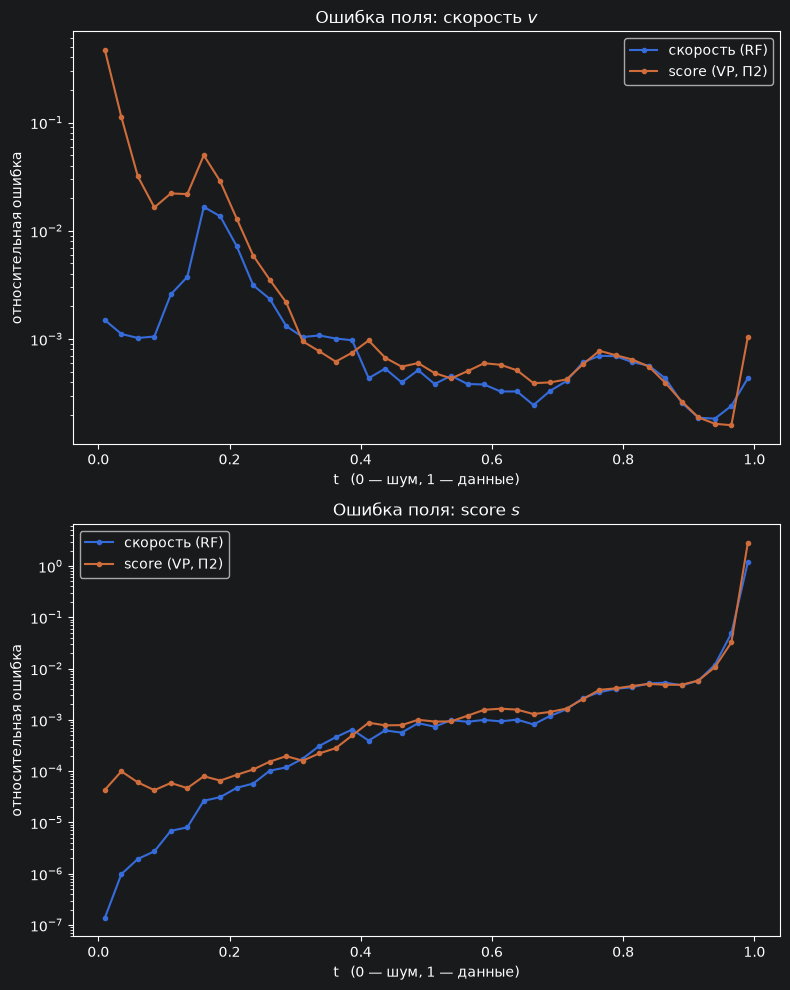

скорость (RF)   : ошибка v при t=0.01 0.0015, в середине 0.0006;  ошибка s в середине 0.0008, при t=0.99 1.19
score (VP, П2)  : ошибка v при t=0.01 0.4670, в середине 0.0007;  ошибка s в середине 0.0009, при t=0.99 2.87


In [3]:
fe = load_or_run('results/p4_field_error.pt', field_error)
_, losses_rf = load_rf_model()

fig, axes = plt.subplots(2, 1, figsize=(8, 10))  # 2 строки, 1 столбец

for ax, key, title in [(axes[0], 'v', 'скорость $v$'), (axes[1], 's', 'score $s$')]:
    for k, c in [('rf', 'C0'), ('vp', 'C1')]:
        ax.plot(fe['t'], fe[k][key], 'o-', ms=3, color=c, label=FIELD_NAMES[k])
    ax.set_yscale('log')
    ax.set_xlabel('t   (0 — шум, 1 — данные)')
    ax.set_ylabel('относительная ошибка')
    ax.set_title(f'Ошибка поля: {title}')
    ax.legend()

plt.tight_layout()
plt.savefig('figures/p4_field_error.png', dpi=150)
plt.show()

for k in ['rf', 'vp']:
    print(f"{FIELD_NAMES[k]:16}: ошибка v при t=0.01 {fe[k]['v'][0]:.4f}, в середине {np.median(fe[k]['v']):.4f};"
          f"  ошибка s в середине {np.median(fe[k]['s']):.4f}, при t=0.99 {fe[k]['s'][-1]:.2f}")

Обе сети точны в середине пути (ошибка $\sim10^{-3}$–$10^{-4}$). На концах — ровно предсказанное: у score из модели скорости ошибка взлетает до $\sim1$ при $t\to1$, у скорости из VP-модели — до 0.5 при $t\to0$. Пересчёт «score ↔ скорость» плохо обусловлен на противоположных концах пути. Это важно для П4: в члене $\tfrac12 g^2 s$ семейства участвует именно score, и у модели скорости он плох как раз там, где выдаются финальные сэмплы.

## 2. Главный результат: тепловые карты «качество vs $(g, \text{NFE})$»

Верхний ряд — $g$ постоянный (как в задании). Нижний — $g_t = g\,(1-t)$: шум затухает к данным (тоже член семейства, маргиналы те же). Цвет и число — Sliced W1, **светлее = лучше**; шкала общая, логарифмическая. Пол метрики — 0.034.

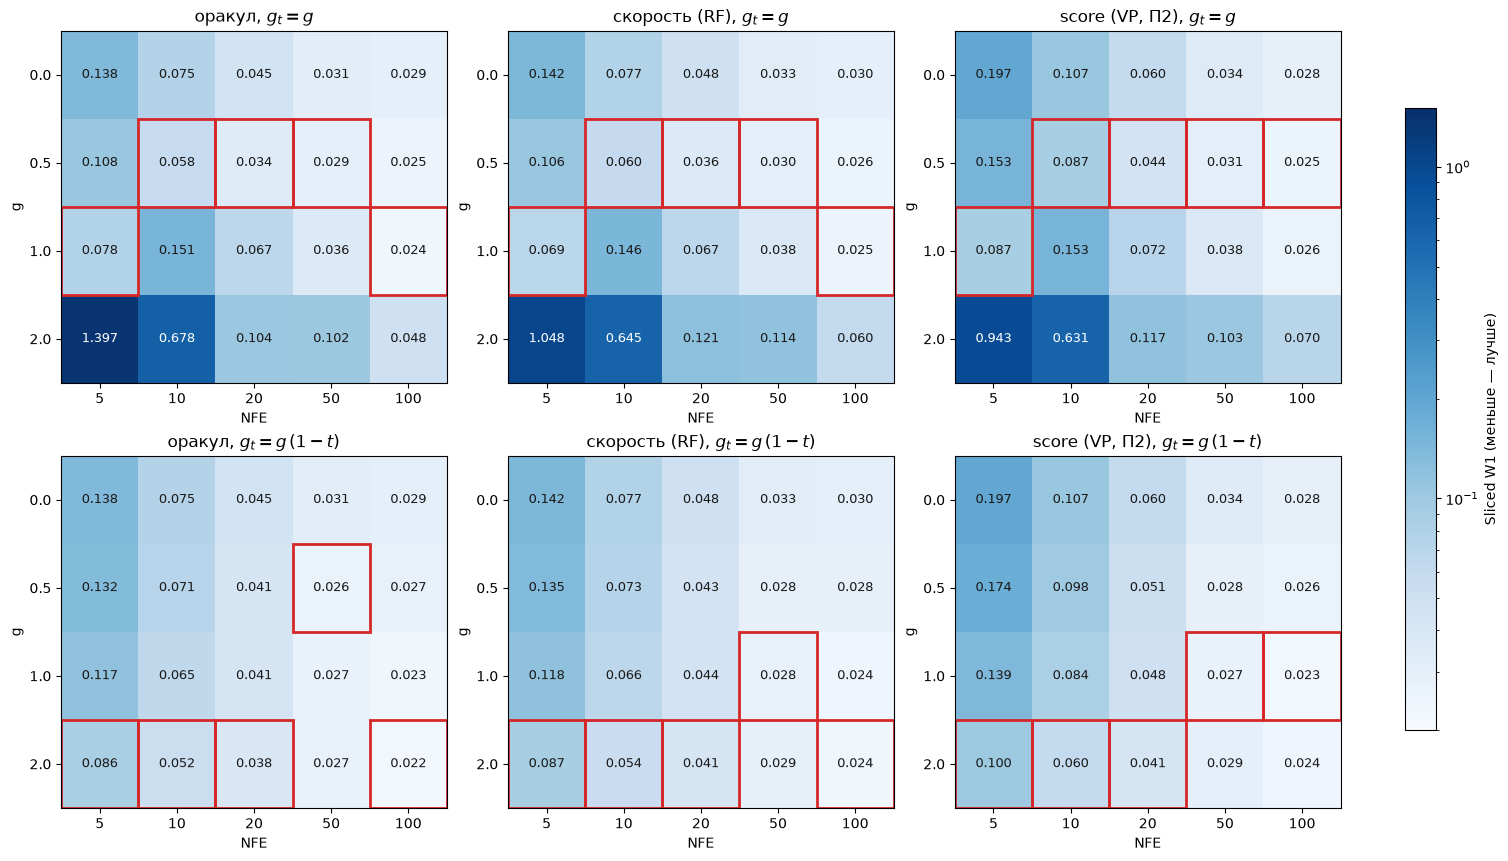

Красная рамка — лучший g при данном NFE (в каждом столбце).


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), constrained_layout=True)
norm = LogNorm(vmin=0.02, vmax=1.5)
for r_i, (sch, sch_name) in enumerate([('const', r'$g_t = g$'), ('sigma', r'$g_t = g\,(1-t)$')]):
    for c_i, f in enumerate(FIELD_NAMES):
        M = np.nanmean(res[(f, sch)]['sw'], axis=2)
        ax = axes[r_i, c_i]
        im = ax.imshow(M, cmap='Blues', norm=norm, aspect='auto')
        for i in range(len(GS)):
            for j in range(len(NFES4)):
                v = M[i, j]
                ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=9,
                        color='white' if v > 0.25 else '#1a1a1a')
        for j in range(len(NFES4)):
            i_best = int(np.nanargmin(M[:, j]))
            ax.add_patch(plt.Rectangle((j - .5, i_best - .5), 1, 1, fill=False, ec='#d62728', lw=2))
        ax.set_xticks(range(len(NFES4)), NFES4); ax.set_yticks(range(len(GS)), GS)
        ax.set_xlabel('NFE'); ax.set_ylabel('g')
        ax.set_title(f'{FIELD_NAMES[f]}, {sch_name}')
fig.colorbar(im, ax=axes, shrink=0.8, label='Sliced W1 (меньше — лучше)')
plt.savefig('figures/p4_heatmaps.png', dpi=150); plt.show()
print('Красная рамка — лучший g при данном NFE (в каждом столбце).')

### То же семейством кривых

SW1 по NFE, каждая линия — одно значение $g$. Сплошные — оракул, пунктир — score-модель из П2 (у модели скорости кривые почти совпадают с оракулом, см. карты). Серая полоса — пол метрики.

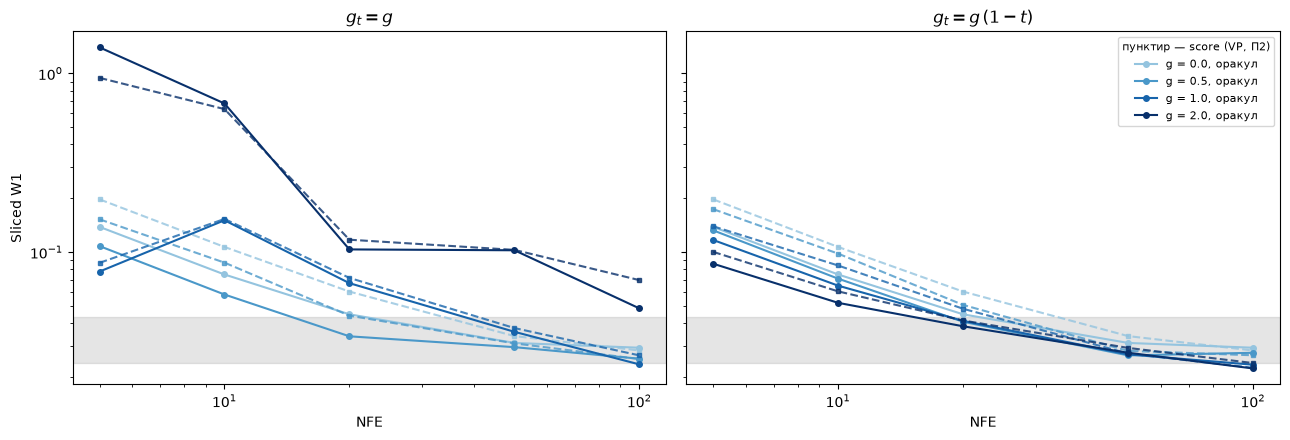

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = plt.cm.Blues(np.linspace(0.4, 1.0, len(GS)))
for ax, (sch, sch_name) in zip(axes, [('const', r'$g_t = g$'), ('sigma', r'$g_t = g\,(1-t)$')]):
    for i, g in enumerate(GS):
        ax.plot(NFES4, np.nanmean(res[('oracle', sch)]['sw'][i], 1), '-o', ms=4, color=colors[i], label=f'g = {g}, оракул')
        ax.plot(NFES4, np.nanmean(res[('vp', sch)]['sw'][i], 1), '--s', ms=3, color=colors[i], alpha=0.8)
    ax.axhspan(floor['sw'].mean() - floor['sw'].std(), floor['sw'].mean() + floor['sw'].std(), color='gray', alpha=0.2)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('NFE'); ax.set_title(sch_name)
axes[0].set_ylabel('Sliced W1'); axes[1].legend(fontsize=8, title='пунктир — score (VP, П2)', title_fontsize=8)
plt.tight_layout(); plt.savefig('figures/p4_curves.png', dpi=150); plt.show()

## 3. Разложение ошибки: модель против дискретизации

Задание предлагает так: **разница «модель − оракул» при одних $(g,\text{NFE})$ — ошибка модели**, разница по NFE у оракула — ошибка дискретизации. Ниже — ошибка модели для score-модели из П2 при NFE = 5 и 10, в зависимости от $g$.

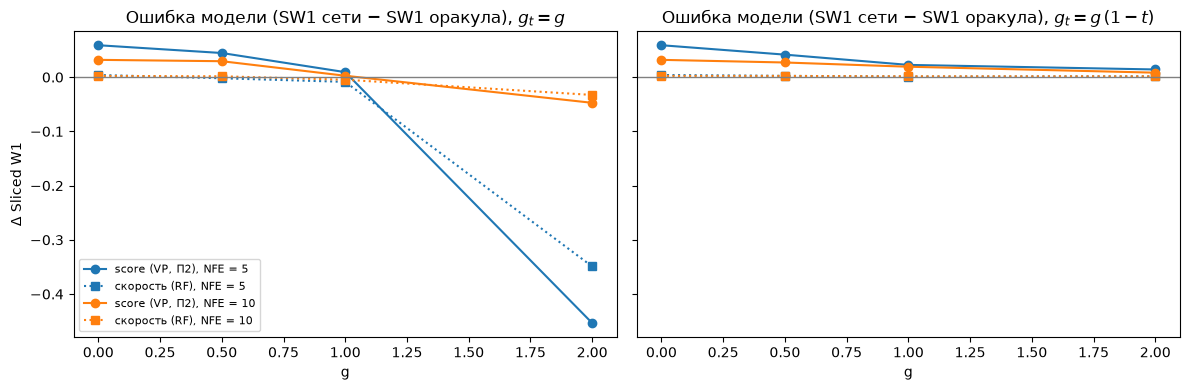

const  NFE=  5: ошибка score-модели по g [0.0, 0.5, 1.0, 2.0]: +0.059  +0.045  +0.009  -0.453
const  NFE= 10: ошибка score-модели по g [0.0, 0.5, 1.0, 2.0]: +0.032  +0.029  +0.003  -0.047
sigma  NFE=  5: ошибка score-модели по g [0.0, 0.5, 1.0, 2.0]: +0.059  +0.042  +0.023  +0.014
sigma  NFE= 10: ошибка score-модели по g [0.0, 0.5, 1.0, 2.0]: +0.032  +0.027  +0.019  +0.008


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (sch, sch_name) in zip(axes, [('const', r'$g_t = g$'), ('sigma', r'$g_t = g\,(1-t)$')]):
    for j, nfe in enumerate(NFES4[:2]):
        for f, mk in [('vp', 'o'), ('rf', 's')]:
            gap = np.nanmean(res[(f, sch)]['sw'][:, j], 1) - np.nanmean(res[('oracle', sch)]['sw'][:, j], 1)
            ax.plot(GS, gap, marker=mk, ls='-' if f == 'vp' else ':', color=f'C{j}',
                    label=f'{FIELD_NAMES[f]}, NFE = {nfe}')
    ax.axhline(0, color='gray', lw=1); ax.set_xlabel('g'); ax.set_title(f'Ошибка модели (SW1 сети − SW1 оракула), {sch_name}')
axes[0].set_ylabel('Δ Sliced W1'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/p4_model_error.png', dpi=150); plt.show()

for sch in ['const', 'sigma']:
    for j, nfe in enumerate(NFES4[:2]):
        gap = np.nanmean(res[('vp', sch)]['sw'][:, j], 1) - np.nanmean(res[('oracle', sch)]['sw'][:, j], 1)
        print(f'{sch:6} NFE={nfe:3}: ошибка score-модели по g {GS}: ' + '  '.join(f'{v:+.3f}' for v in gap))

## 4. Почему постоянный $g$ ведёт себя странно

На верхних картах при $g=1$ качество зависит от NFE немонотонно (NFE = 5 лучше, чем 10), а при $g=2$ и малом NFE сэмплер разваливается (SW1 ≈ 1). Причина — **жёсткость** слагаемого $\tfrac12 g^2\nabla\log p_t$ у данных.

Около одной моды $\nabla\log p_t(x) \approx -(x-m)/v_t$, где $v_t = t^2 s_k^2 + (1-t)^2$ — дисперсия моды; у данных $v_t\to s_k^2 = 0.0625$. Шаг Эйлера по этому слагаемому умножает отклонение от центра на $1 - \Delta t\,g^2/(2v_t)$:
* при $g=1$, NFE = 10: множитель $1 - 0.098\cdot 8 \approx 0.2$ — кучка сжимается в 5 раз за шаг, а последний шаг идёт без шума и не «доливает» разброс;
* при $g=2$, NFE = 5: множитель $1 - 0.2\cdot 32 \approx -5$ — схема неустойчива, точки разлетаются.

Проверим прямо: среднеквадратичная ширина кучки у сэмплов оракула против данных.

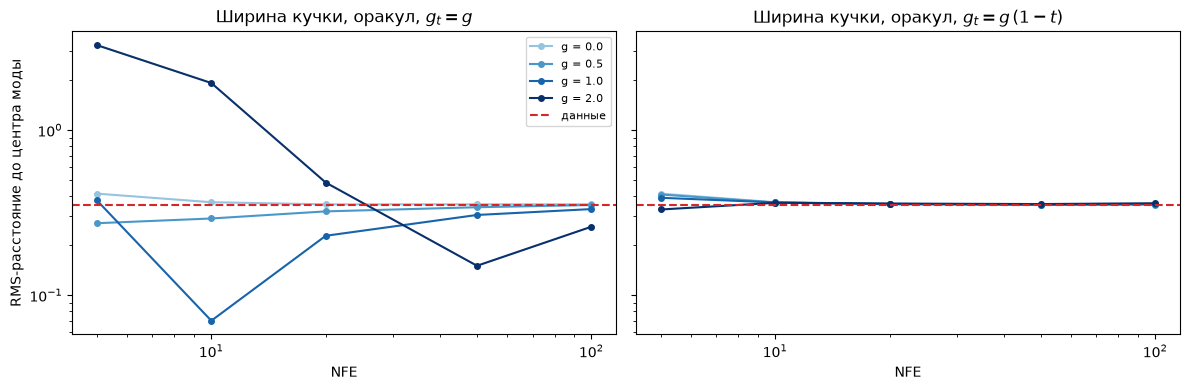

ширина в данных: 0.353
const g=1, NFE=10: 0.07 | sigma g=1, NFE=10: 0.364


In [6]:
def width(x):
    return (x - mix.means[mix.nearest_mode(x)]).norm(dim=1).pow(2).mean().sqrt().item()

f_or = get_field('oracle'); ref = reference_sample()
W = {sch: np.array([[width(sample_family(f_or, g, N4, n, T0, T1, generator=torch.Generator().manual_seed(0), schedule=sch))
                     for n in NFES4] for g in GS]) for sch in ['const', 'sigma']}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sch, name in [(axes[0], 'const', r'$g_t = g$'), (axes[1], 'sigma', r'$g_t = g\,(1-t)$')]:
    for i, g in enumerate(GS):
        ax.plot(NFES4, W[sch][i], '-o', ms=4, color=colors[i], label=f'g = {g}')
    ax.axhline(width(ref), color='#d62728', ls='--', label='данные')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('NFE'); ax.set_title(f'Ширина кучки, оракул, {name}')
axes[0].set_ylabel('RMS-расстояние до центра моды'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/p4_width.png', dpi=150); plt.show()
print('ширина в данных:', round(width(ref), 3))
print('const g=1, NFE=10:', round(W['const'][2, 1], 3), '| sigma g=1, NFE=10:', round(W['sigma'][2, 1], 3))

При $g_t = g(1-t)$ коэффициент $g_t^2$ у данных стремится к нулю, жёсткость исчезает, и ширина кучек правильная при любом $g$.

### Как выглядят сэмплы

Оракул, NFE = 10.

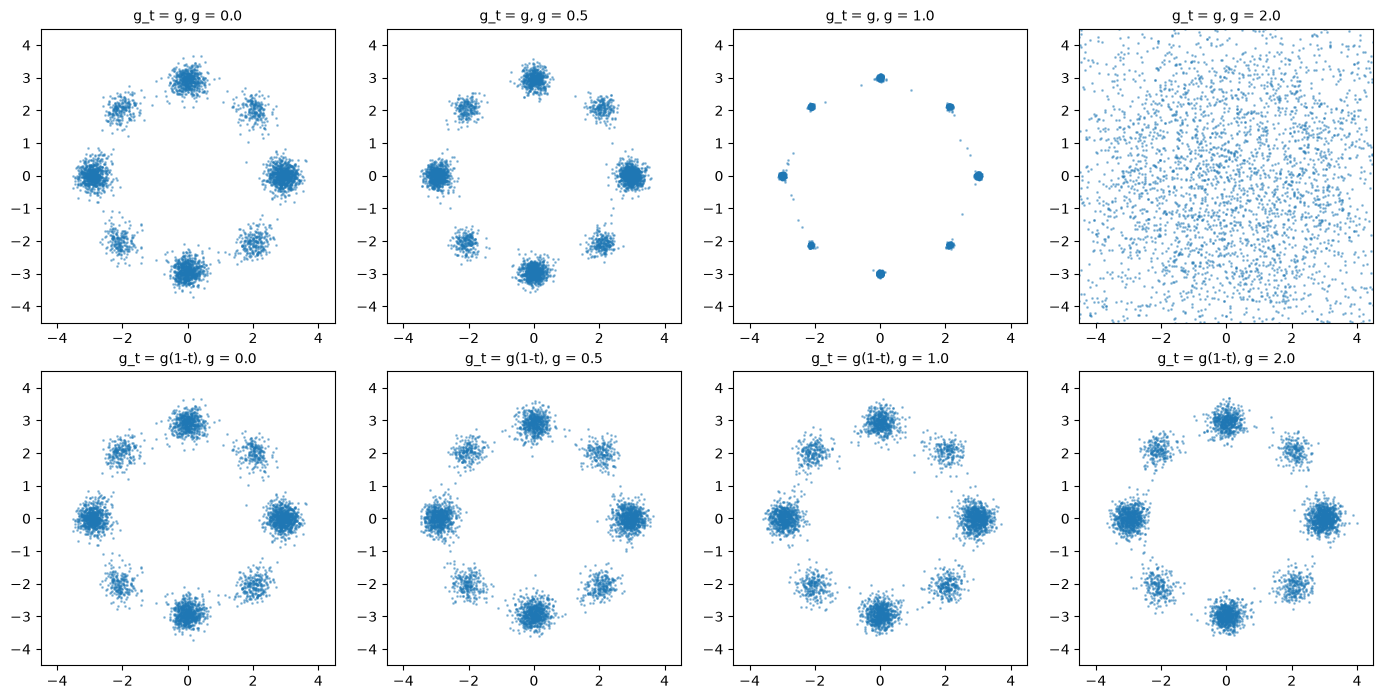

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for r_i, (sch, name) in enumerate([('const', 'g_t = g'), ('sigma', 'g_t = g(1-t)')]):
    for c_i, g in enumerate(GS):
        x = sample_family(f_or, g, 4000, 10, T0, T1, generator=torch.Generator().manual_seed(0), schedule=sch)
        ax = axes[r_i, c_i]; ax.scatter(*x.T, s=1, alpha=0.4)
        ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect('equal')
        ax.set_title(f'{name}, g = {g}', fontsize=10)
plt.tight_layout(); plt.savefig('figures/p4_samples.png', dpi=120); plt.show()

## Выводы

1. **Маргиналы действительно общие.** При NFE = 100 все $g$ и все три поля дают SW1 ≈ 0.02–0.03, то есть уровень пола метрики: семейство SDE из Т4 работает и с точным полем, и с обеими сетями (за исключением неустойчивого $g = 2$ при постоянном $g$, которому нужно больше шагов).

2. **Гипотеза «с оракулом и малым NFE лучше ODE» не подтвердилась.** Шум помогает даже с точным полем — если он затухает к данным: при $g_t = 2(1-t)$ и NFE = 5 SW1 = 0.086 против 0.138 у ODE. С постоянным $g$ помогает только умеренный шум ($g \le 1$), а $g = 2$ при малом NFE ломает сэмплер из-за жёсткости $\tfrac12 g^2\nabla\log p$ у данных.

3. **Вторая часть гипотезы подтвердилась: шум исправляет ошибку модели.** У score-модели из П2 скорость неточна у шума (пересчёт делит на $t$), и в ODE это даёт заметный проигрыш оракулу (0.197 против 0.138 при NFE = 5). С $g_t = 2(1-t)$ разрыв падает в 4 раза (0.100 против 0.086): стохастический сэмплер «забывает» ошибки начала траектории. Модель скорости почти не отличается от оракула при любом $g$.

4. **Цена шума — доли мод.** По TV мод большой $g$ при малом NFE немного хуже ODE (0.085 против 0.073 у оракула при NFE = 5): шум улучшает форму кучек, но слегка размывает веса.

5. **Пересчёт «score ↔ скорость» плохо обусловлен на концах:** score из модели скорости — у данных, скорость из score-модели — у шума. Поэтому шум в семействе нужно убирать именно у данных, где score от модели скорости хуже всего.

**В одном предложении:** при малом NFE шум, затухающий к данным ($g_t = g(1-t)$, $g\approx2$), улучшает качество и оракула, и обученной модели (у score-модели из П2 в 4 раза сокращает её ошибку), а постоянный $g$ помогает только умеренным и ломает сэмплер, если он велик.